### VIX index correlation V5

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import fisher_exact
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '2010-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def extract_csv(
    start: str,
    end: str,
    output_dir: str,
    file_name: str,
    csv_df: pd.DataFrame,
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / file_name
    # 重複するファイルがある場合は削除
    if output_path.exists():
        output_path.unlink()
    # 保存
    df = csv_df.copy()
    df = df.reset_index()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]
    df.to_csv(output_path)
    return output_path

#### VIX時系列を取得

In [5]:
vix_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^VIX",
    market=None,
)
vix_df.tail()

取得件数: 4438


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4433,1318186,^VIX,None,2026-10-19,18.440001,18.930000,17.389999,18.370001,0,16.544,...,14.980537,34.171433,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1322446,^VIX,None,2026-10-20,17.309999,19.129999,17.250000,18.420000,0,17.106,...,14.941097,37.287629,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332259,^VIX,None,2026-10-21,16.680000,17.580000,16.510000,17.250000,0,17.522,...,14.939329,40.258687,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4436,1332252,^VIX,None,2026-10-22,19.030001,20.309999,17.709999,18.290001,0,17.670,...,14.930694,43.767609,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4437,1332260,^VIX,None,2026-10-23,19.450001,20.660000,18.870001,19.180000,0,18.302,...,14.955775,46.422778,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500時系列を取得

In [6]:
sp500_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
)
sp500_df.tail()

取得件数: 4436


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4431,1318187,^GSPC,None,2026-10-19,7690.729980,7731.180176,7684.790039,7702.770020,4587260000,7740.970020,...,7660.913979,12.037907,True,NaN,NaN,NaN,NaN,NaN,NaN,False
4432,1322447,^GSPC,None,2026-10-20,7712.569824,7748.419922,7668.029785,7679.009766,5004770000,7717.717969,...,7667.092991,10.475540,False,NaN,7723.472031,NaN,NaN,NaN,NaN,False
4433,1322449,^GSPC,None,2026-10-21,7757.169922,7770.399902,7709.339844,7736.430176,4921480000,7710.167969,...,7678.297169,14.249125,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4434,1332253,^GSPC,None,2026-10-22,7663.430176,7702.939941,7637.359863,7694.620117,5972620000,7711.629980,...,7684.296682,16.289593,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4435,1332261,^GSPC,None,2026-10-23,7623.680176,7660.149902,7612.069824,7637.180176,5062330000,7690.002051,...,7682.095087,15.555366,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Nasdaq100時系列を取得

In [7]:
qqq_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
)
qqq_df.tail()

取得件数: 4259


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
4254,1322442,^IXIC,None,2026-10-19,26430.890625,26613.150391,26344.669922,26395.289062,7537660000,26719.882031,...,26505.571508,51.967899,False,NaN,26916.25625,NaN,NaN,NaN,NaN,False
4255,1322448,^IXIC,None,2026-10-20,26424.820312,26601.710938,26179.730469,26332.919922,7660360000,26558.719922,...,26526.314282,46.008708,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4256,1322483,^IXIC,None,2026-10-21,26702.859375,26778.900391,26507.070312,26601.730469,7818990000,26472.737891,...,26575.880210,46.059933,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4257,1332254,^IXIC,None,2026-10-22,26008.859375,26359.410156,25918.089844,26308.410156,9012120000,26458.266016,...,26568.604422,43.797490,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4258,1332262,^IXIC,None,2026-10-23,25955.339844,26111.619141,25866.150391,25893.949219,6554790000,26306.459766,...,26497.683270,38.120038,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### UVXY時系列を取得

In [8]:
uvxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="UVXY",
    market=None,
)
uvxy_df.tail()

取得件数: 3786


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3781,1326265,UVXY,None,2026-10-19,17.379999,17.730000,16.870001,17.520000,18879800,16.520,...,16.8940,-92.930931,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1326266,UVXY,None,2026-10-20,17.180000,18.139999,16.809999,17.870001,17214800,16.916,...,16.8868,-89.780586,True,16.916,NaN,NaN,NaN,NaN,NaN,False
3783,1326267,UVXY,None,2026-10-21,16.799999,17.420000,16.709999,16.870001,14922300,17.090,...,16.8416,-88.875608,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332255,UVXY,None,2026-10-22,18.410000,18.969999,17.170000,17.459999,23934800,17.156,...,16.8448,-85.575856,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3785,1332263,UVXY,None,2026-10-23,18.760000,19.860001,18.610001,19.170000,20030600,17.778,...,16.9132,-78.233587,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### SVXY時系列を取得

In [9]:
svxy_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="SVXY",
    market=None,
)
svxy_df.tail()

取得件数: 3786


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3781,1330049,SVXY,None,2026-10-19,63.259998,63.849998,62.869999,63.090000,3850300,64.598,...,63.430980,91.381371,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3782,1330050,SVXY,None,2026-10-20,63.540001,63.990002,62.369999,62.689999,2225300,64.030,...,63.423886,87.483992,False,NaN,64.1664,NaN,NaN,NaN,NaN,False
3783,1330051,SVXY,None,2026-10-21,63.900002,64.150002,63.259998,63.930000,1611100,63.740,...,63.503574,86.096645,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3784,1332256,SVXY,None,2026-10-22,61.980000,63.520000,61.259998,63.250000,3109700,63.628,...,63.470040,82.784086,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3785,1332264,SVXY,None,2026-10-23,61.639999,61.740002,60.340000,61.150002,1988200,62.822,...,63.175975,74.280714,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VXX時系列を取得

In [10]:
vxx_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VXX",
    market=None,
)
vxx_df.tail()

取得件数: 2199


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
2194,1332246,VXX,None,2026-10-19,17.790001,18.010000,17.434999,17.865,24216200,17.143,...,16.985198,-91.564928,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2195,1332247,VXX,None,2026-10-20,17.570000,18.280001,17.379999,18.080,13604000,17.421,...,16.985904,-88.474345,True,17.421,NaN,NaN,NaN,NaN,NaN,False
2196,1332248,VXX,None,2026-10-21,17.389999,17.785000,17.299999,17.400,10846000,17.545,...,16.987596,-87.526680,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2197,1332257,VXX,None,2026-10-22,18.480000,18.865000,17.639999,17.770,19858300,17.585,...,16.987295,-84.299496,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2198,1332265,VXX,None,2026-10-23,18.719999,19.450001,18.625000,18.990,16157700,18.021,...,16.917382,-75.898574,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXM時系列を取得

In [11]:
vixm_df = request_api.fetch_stock_timeseries_data(
    start_date=start,
    end_date=end,
    code="VIXM",
    market=None,
)
vixm_df.tail()

取得件数: 3975


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
3970,1332249,VIXM,None,2026-10-19,12.90,12.92,12.76,12.89,307900,12.798,...,12.768912,-94.664048,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3971,1332250,VIXM,None,2026-10-20,13.00,13.07,12.86,13.07,456400,12.876,...,12.778590,-93.229745,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3972,1332251,VIXM,None,2026-10-21,12.99,13.02,12.93,12.97,510100,12.910,...,12.784483,-91.765560,True,12.91,NaN,NaN,NaN,NaN,NaN,False
3973,1332258,VIXM,None,2026-10-22,13.21,13.30,13.01,13.01,307700,12.926,...,12.786325,-89.819005,True,NaN,NaN,NaN,NaN,NaN,NaN,False
3974,1332266,VIXM,None,2026-10-23,13.25,13.41,13.23,13.29,282900,13.046,...,12.775154,-86.566208,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### VIXの各日時点のフィボナッチリトレースメントをローリング計算

In [12]:
fibonacci_retracement_df = fibonacci_retracement.fibonacci_retracement_for_timeseries(
    df=vix_df,
    lookback=120,
)
fibonacci_retracement_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_retracement_0.000,fib_retracement_0.236,fib_retracement_0.382,fib_retracement_0.500,fib_retracement_0.618,fib_retracement_0.786,fib_retracement_1.000
4313,2026-10-19,18.370001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4314,2026-10-20,18.420000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4315,2026-10-21,17.250000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4316,2026-10-22,18.290001,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25
4317,2026-10-23,19.180000,downward,21.25,14.15,14.15,15.8256,16.8622,17.7,18.5378,19.7306,21.25


#### VIXの各日時点のフィボナッチエクステンションをローリング計算

In [13]:
fibonacci_extension_df = fibonacci_extension_v2.fibonacci_extension_for_timeseries(
    df=vix_df,
    lookback=120,
    extension_direction="up"
)
fibonacci_extension_df.tail()

,date,close,fib_trend,fib_top,fib_bottom,fib_extension_1.000,fib_extension_1.272,fib_extension_1.618,fib_extension_2.000,fib_extension_2.618,fib_extension_4.236,distance_ext_1272,distance_ext_1618,distance_ext_2000,distance_ext_2618,distance_ext_4236
4313,2026-10-19,18.370001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.811199,-7.267799,-9.980000,-14.367800,-25.855600
4314,2026-10-20,18.420000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.761200,-7.217800,-9.930000,-14.317801,-25.805601
4315,2026-10-21,17.250000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-5.931200,-8.387800,-11.100000,-15.487801,-26.975601
4316,2026-10-22,18.290001,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.891199,-7.347799,-10.059999,-14.447800,-25.935600
4317,2026-10-23,19.180000,downward,21.25,14.15,21.25,23.1812,25.6378,28.35,32.737801,44.225601,-4.001200,-6.457800,-9.170000,-13.557800,-25.045601


#### データ統合

In [14]:
# データフレームのコピーを作成
vix_work = vix_df.copy()
sp500_work = sp500_df.copy()
qqq_work = qqq_df.copy()
uvxy_work = uvxy_df.copy()
svxy_work = svxy_df.copy()
vxx_work = vxx_df.copy()
vixm_work = vixm_df.copy()
# 必要列のみ抽出
vix_work = vix_work[["date", "close"]].rename(
    columns={"close": "vix"}
)
# S&P500の必要列のみ抽出
sp500_work = sp500_work[["date", "close"]].rename(
    columns={"close": "sp500"}
)
# QQQの必要列のみ抽出
qqq_work = qqq_work[["date", "close"]].rename(
    columns={"close": "qqq"}
)
# UVXYの必要列のみ抽出
uvxy_work = uvxy_work[["date", "close", "volume"]].rename(
    columns={
        "close": "uvxy",
        "volume": "uvxy_volume"
    }
)
# SVXYの必要列のみ抽出
svxy_work = svxy_work[["date", "close", "volume"]].rename(
    columns={
        "close": "svxy",
        "volume": "svxy_volume"
    }
)
# VXXの必要列のみ抽出
vxx_work = vxx_work[["date", "close", "volume"]].rename(
    columns={
        "close": "vxx",
        "volume": "vxx_volume"
    }
)
# VIXMの必要列のみ抽出
vixm_work = vixm_work[["date", "close", "volume"]].rename(
    columns={
        "close": "vixm",
        "volume": "vixm_volume"
    }
)
# 結合用のデータフレームを作成
research_df = (
    vix_work
    .merge(sp500_work, on="date",how="left")
    .merge(qqq_work, on="date", how="left")
    .merge(uvxy_work, on="date", how="left")
    .merge(svxy_work, on="date", how="left")
    .merge(vxx_work, on="date", how="left")
    .merge(vixm_work, on="date", how="left")
)
# 結合結果の形状を確認
print(research_df.shape)
display(
    research_df.head()
)

(4438, 12)


,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,vixm,vixm_volume
0,2009-03-09,49.349998,680.760010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-03-10,49.680000,679.280029,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-03-11,43.349998,719.590027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-03-12,43.529999,720.890015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-03-13,40.990002,751.969971,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Fibonacci結果を統合

In [15]:
# Fibonacci系列を index 基準で結合（lookback 分の先頭行は NaN になる）
fib_columns = {
    "fib_retracement": fibonacci_retracement_df["fib_retracement_0.618"],
    "fib_extension": fibonacci_extension_df["fib_extension_1.618"],
    "fib_top": fibonacci_extension_df["fib_top"],
    "fib_bottom": fibonacci_extension_df["fib_bottom"],
}
# Fibonacci系列の各列を research_df に追加する
for column, series in fib_columns.items():
    research_df[column] = series.reindex(research_df.index)

# 結合結果を表示
display(
    research_df[
        [
            "date",
            "vix",
            "fib_retracement",
            "fib_extension",
        ]
    ].tail()
)

,date,vix,fib_retracement,fib_extension
4433,2026-10-19,18.370001,NaN,NaN
4434,2026-10-20,18.420000,NaN,NaN
4435,2026-10-21,17.250000,NaN,NaN
4436,2026-10-22,18.290001,NaN,NaN
4437,2026-10-23,19.180000,NaN,NaN


##### GapRatio特徴量作成

In [16]:
# ギャップとギャップ比率を計算
research_df["gap_ret"] = (
    research_df["fib_retracement"]
    -
    research_df["vix"]
)
# ギャップの比率を計算するための準備
research_df["gap_ext"] = (
    research_df["fib_extension"]
    -
    research_df["vix"]
)
# ギャップ比率を計算
research_df["gap_ret_ratio"] = (
    research_df["gap_ret"]
    /
    research_df["vix"]
)
# ギャップ比率を計算するための準備
research_df["gap_ext_ratio"] = (
    research_df["gap_ext"]
    /
    research_df["vix"]
)
# ギャップ比率の表示
display(
    research_df[
        [
            "date",
            "gap_ret_ratio",
            "gap_ext_ratio"
        ]
    ].tail()
)

,date,gap_ret_ratio,gap_ext_ratio
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN
4437,2026-10-23,NaN,NaN


##### GapVelocity・GapAcceleration作成

In [17]:
# ギャップ比率の変化率（速度）と加速度を計算
research_df["gap_velocity"] = (
    research_df["gap_ext_ratio"]
    .diff()
)
# ギャップ比率の変化率（速度）の表示
research_df["gap_acceleration"] = (
    research_df["gap_velocity"]
    .diff()
)

##### 出来高特徴量作成

In [18]:
volume_cols = [
    "uvxy_volume",
    "svxy_volume",
    "vxx_volume",
    "vixm_volume"
]
# 各銘柄の出来高の20日移動平均と比率を計算
for col in volume_cols:
    # 20日移動平均を計算
    research_df[f"{col}_ma20"] = (
        research_df[col]
        .rolling(20)
        .mean()
    )
    # 出来高と移動平均の比率を計算
    research_df[f"{col}_ratio"] = (
        research_df[col]
        /
        research_df[f"{col}_ma20"]
    )

##### 出来高Z-Score作成

In [19]:
for col in volume_cols:
    # 60日移動平均と標準偏差を計算
    rolling_mean = (
        research_df[col]
        .rolling(60)
        .mean()
    )
    # 計算結果を確認
    rolling_std = (
        research_df[col]
        .rolling(60)
        .std()
    )

    # Zスコアを計算
    research_df[f"{col}_z"] = (
        research_df[col]
        -
        rolling_mean
    ) / rolling_std

##### Fear Flow作成

In [20]:
# 恐怖フローのバランスを計算
research_df["fear_flow_balance"] = (
    research_df["uvxy_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランス2を計算
research_df["fear_flow_balance_2"] = (
    research_df["vxx_volume_z"]
    -
    research_df["svxy_volume_z"]
)
# 恐怖フローのバランスを表示
display(
    research_df[
        [
            "date",
            "fear_flow_balance",
            "fear_flow_balance_2"
        ]
    ].tail()
)

,date,fear_flow_balance,fear_flow_balance_2
4433,2026-10-19,NaN,NaN
4434,2026-10-20,NaN,NaN
4435,2026-10-21,NaN,NaN
4436,2026-10-22,NaN,NaN
4437,2026-10-23,NaN,NaN


##### 未来目的変数作成

In [21]:
for period in [1, 2, 3, 4, 5, 10, 20, 40]:
    research_df[
        f"vix_{period}d_return"
    ] = (
        research_df["vix"]
        .shift(-period)
        /
        research_df["vix"]
        -
        1.0
    )
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,fear_flow_balance,fear_flow_balance_2,vix_1d_return,vix_2d_return,vix_3d_return,vix_4d_return,vix_5d_return,vix_10d_return,vix_20d_return,vix_40d_return
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,...,NaN,NaN,0.002722,-0.060969,-0.004355,0.044094,NaN,NaN,NaN,NaN
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,...,NaN,NaN,-0.063518,-0.007058,0.041260,NaN,NaN,NaN,NaN,NaN
4435,2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,...,NaN,NaN,0.060290,0.111884,NaN,NaN,NaN,NaN,NaN,NaN
4436,2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,...,NaN,NaN,0.048660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4437,2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### 株価指数リターン作成

In [22]:
INDEX_SYMBOLS = ["qqq", "spy"]
FORECAST_PERIODS = [1, 2, 3, 4, 5]
# 各インデックスシンボルについて、n日間のリターンを算出する
for symbol in INDEX_SYMBOLS:
    # 使用する終値カラムを指定する
    close_col = "close"
    # データフレームを取得する
    source_df = {"qqq": qqq_df, "spy": sp500_df}[symbol]
    # 各予測期間について、n日間のリターンを計算する
    for n in FORECAST_PERIODS:
        # 計算結果を格納するカラム名を作成する
        source_df[f"{symbol}_{n}d_return"] = (
            source_df[close_col].shift(-n)
            /
            source_df[close_col]
            -
            1.0
        )

#### リサーチデータへ統合

In [23]:
# "date"カラムをインデックスに設定し、各インデックスのリターンカラムをresearch_dfに結合する
for df in [qqq_df, sp500_df]:
    # "date"カラムが存在する場合はインデックスに設定する
    if "date" in df.columns:
        df.set_index("date", inplace=True)
# research_dfに各インデックスのリターンカラムを結合する準備が整った
research_df = research_df.merge(
    qqq_df.reset_index()[["date"] + [c for c in qqq_df.columns if "_return" in c]],
    on="date", how="left",
)
# research_dfにSPYのリターンカラムを結合する
research_df = research_df.merge(
    sp500_df.reset_index()[["date"] + [c for c in sp500_df.columns if "_return" in c]],
    on="date", how="left",
)
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,qqq_1d_return,qqq_2d_return,qqq_3d_return,qqq_4d_return,qqq_5d_return,spy_1d_return,spy_2d_return,spy_3d_return,spy_4d_return,spy_5d_return
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,...,-0.002363,0.007821,-0.003291,-0.018994,NaN,-0.003085,0.004370,-0.001058,-0.008515,NaN
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,...,0.010208,-0.000931,-0.016670,NaN,NaN,0.007478,0.002033,-0.005447,NaN,NaN
4435,2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,...,-0.011026,-0.026607,NaN,NaN,NaN,-0.005404,-0.012829,NaN,NaN,NaN
4436,2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,...,-0.015754,NaN,NaN,NaN,NaN,-0.007465,NaN,NaN,NaN,NaN
4437,2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"research_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc[start:end]
df.to_csv(output_path)
df.head()

,index,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,qqq_1d_return,qqq_2d_return,qqq_3d_return,qqq_4d_return,qqq_5d_return,spy_1d_return,spy_2d_return,spy_3d_return,spy_4d_return,spy_5d_return
date,,,,,,,,,,,,,,,,,,,,,
2010-01-04,208,21.680000,1116.560059,2294.409912,NaN,NaN,NaN,NaN,NaN,NaN,...,0.005605,0.005797,0.001604,-0.000946,0.013237,0.014419,0.017151,0.017652,0.021459,0.026331
2010-01-05,209,20.049999,1132.660034,2307.270020,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000191,-0.003979,-0.006514,0.007589,-0.004330,0.002693,0.003187,0.006939,0.011742,0.009844
2010-01-06,210,19.590000,1135.709961,2307.709961,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.004169,-0.006704,0.007397,-0.004520,-0.007908,0.000493,0.004235,0.009025,0.007132,0.001409
2010-01-07,211,19.680000,1136.270020,2298.090088,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.002546,0.011614,-0.000352,-0.003755,0.002271,0.003740,0.008528,0.006636,0.000915,0.008282
2010-01-08,212,19.270000,1140.520020,2292.239990,NaN,NaN,NaN,NaN,NaN,NaN,...,0.014196,0.002199,-0.001213,0.004829,0.010793,0.004770,0.002885,-0.002814,0.004524,0.006313


#### 1. 分析目的

##### 目的

VIX関連ETFの出来高水準だけでなく、

- N営業日前比出来高変化率
- 出来高ROC (Rate of Change)
- 出来高Z-score変化量

に市場ストレスの先行シグナルとしての
情報価値が存在するか検証する。

Later1の早期警戒シグナル候補を探索する。

#### 2. 出来高変化率特徴量作成

##### 目的

N営業日前からの出来高増減率を計算する。

In [25]:
VOLUME_COLS = ["uvxy_volume", "svxy_volume", "vxx_volume"]
LOOKBACK_DAYS = [1, 3, 5, 10]
# 各出来高列に対して、指定したルックバック期間の変化率を計算する
for volume_col in VOLUME_COLS:
    # 各ルックバック期間に対して出来高の変化を計算する
    for n in LOOKBACK_DAYS:
        # 前回の値を取得し、0を欠損値に置換する
        base = (research_df[volume_col].shift(n).replace(0, np.nan))
        # 出来高の変化率を計算する
        research_df[f"{volume_col}_change_{n}d"] = (research_df[volume_col] / base - 1.0)

#### 3. 出来高ROC特徴量作成

##### 目的

出来高の変化速度を表現する。

In [26]:
# 各ルックバック期間における出来高の変化率を算出する
for volume_col in VOLUME_COLS:
    # 各出来高列に対してルックバック期間ごとの変化率を計算する
    for n in LOOKBACK_DAYS:
        # 計算結果の列名を作成
        research_df[
            f"{volume_col}_roc_{n}d"
        ] = (research_df[volume_col] - research_df[volume_col].shift(n))

#### 4. 出来高Z-Score作成

##### 目的

出来高異常度を定量化する。

In [27]:
# 各出来高列に対して60日移動平均と標準偏差を用いたZスコアを計算する
for volume_col in VOLUME_COLS:
    # 計算対象の出来高列に対して60日移動平均と標準偏差を計算する
    rolling_mean = (research_df[volume_col].rolling(60).mean())
    # 計算対象の出来高列に対して60日移動平均と標準偏差を用いたZスコアを計算する準備
    rolling_std = (research_df[volume_col].rolling(60).std())
    # 計算結果の列名を作成し、Zスコアを計算してデータフレームに格納する
    research_df[f"{volume_col}_z"] = (research_df[volume_col] - rolling_mean) / rolling_std

#### 5. Z-Score変化量作成

##### 目的

出来高異常が加速した瞬間を捉える。

In [28]:
# Zスコア化された出来高の列について、1日デルタを算出する
for volume_col in VOLUME_COLS:
    # Zスコア化された出来高の列の1日デルタを計算する
    z_col = f"{volume_col}_z"
    # 1日デルタの列名を作成する
    research_df[f"{z_col}_delta_1d"] = (
        research_df[z_col]
        -
        research_df[z_col].shift(1)
    )

#### 6. 目的変数作成

##### 目的

QQQ急落イベントを分類問題として扱う。

In [29]:
# QQQの1日リターンが一定の割合以上下落したかどうかを示すフラグを作成する
research_df["qqq_1d_drop_2"] = (
    research_df["qqq_1d_return"]
    <= -0.02
).astype(int)
# QQQの1日リターンが一定の割合以上下落したかどうかを示すフラグを作成する（3%下落）
research_df["qqq_1d_drop_3"] = (
    research_df["qqq_1d_return"]
    <= -0.03
).astype(int)
# QQQの1日リターンが一定の割合以上下落したかどうかを示すフラグを作成する（5%下落）
research_df["qqq_1d_drop_5"] = (
    research_df["qqq_1d_return"]
    <= -0.05
).astype(int)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"6_target_variable_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
research_df.tail()

,date,vix,sp500,qqq,uvxy,uvxy_volume,svxy,svxy_volume,vxx,vxx_volume,...,vxx_volume_roc_1d,vxx_volume_roc_3d,vxx_volume_roc_5d,vxx_volume_roc_10d,uvxy_volume_z_delta_1d,svxy_volume_z_delta_1d,vxx_volume_z_delta_1d,qqq_1d_drop_2,qqq_1d_drop_3,qqq_1d_drop_5
4433,2026-10-19,18.370001,7702.770020,26395.289062,17.520000,18879800.0,63.090000,3850300.0,17.865,24216200.0,...,-20213700.0,11295900.0,14585300.0,16785200.0,NaN,NaN,NaN,0,0,0
4434,2026-10-20,18.420000,7679.009766,26332.919922,17.870001,17214800.0,62.689999,2225300.0,18.080,13604000.0,...,-10612200.0,1571100.0,8772800.0,3593500.0,NaN,NaN,NaN,0,0,0
4435,2026-10-21,17.250000,7736.430176,26601.730469,16.870001,14922300.0,63.930000,1611100.0,17.400,10846000.0,...,-2758000.0,-33583900.0,-2074300.0,2294800.0,NaN,NaN,NaN,0,0,0
4436,2026-10-22,18.290001,7694.620117,26308.410156,17.459999,23934800.0,63.250000,3109700.0,17.770,19858300.0,...,9012300.0,-4357900.0,7825400.0,9801700.0,NaN,NaN,NaN,0,0,0
4437,2026-10-23,19.180000,7637.180176,25893.949219,19.170000,20030600.0,61.150002,1988200.0,18.990,16157700.0,...,-3700600.0,2553700.0,-28272200.0,9597700.0,NaN,NaN,NaN,0,0,0


#### 7. ROC-AUC評価

##### 目的

出来高変化率特徴量が
QQQ急落イベントを説明できるか確認する。

In [30]:

# 特徴量とターゲットを定義してROC AUCを計算する
FEATURES = [c for c in research_df.columns
    if any(
        key in c
        for key in ["_change_", "_roc_", "_delta_1d"]
    )
]
# ターゲットカラムを定義する
TARGETS = [
    "qqq_1d_drop_2",
    "qqq_1d_drop_3",
    "qqq_1d_drop_5"
]
rows = []
# 各特徴量とターゲットの組み合わせについてROC AUCを計算する
for feature in FEATURES:
    # 各ターゲットに対してROC AUCを計算する
    for target in TARGETS:
        # 欠損値を除外したデータフレームを作成する
        work_df = (
            research_df[[feature, target]]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )
        # ターゲットのユニーク値が2未満の場合はスキップする
        if work_df[target].nunique() < 2:
            continue
        # ROC AUCを計算する
        auc = roc_auc_score(work_df[target], work_df[feature])
        # 計算結果をリストに追加する
        rows.append({
            "feature": feature,
            "target": target,
            "roc_auc": auc
        })
# 計算結果をデータフレームに変換する
auc_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"7_auc_df_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = auc_df.copy()
df.to_csv(output_path)
display(auc_df.sort_values("roc_auc", ascending=False).head(50))

,feature,target,roc_auc
59,svxy_volume_roc_10d,qqq_1d_drop_5,0.950209
56,svxy_volume_roc_5d,qqq_1d_drop_5,0.895266
23,svxy_volume_change_10d,qqq_1d_drop_5,0.886092
20,svxy_volume_change_5d,qqq_1d_drop_5,0.859776
53,svxy_volume_roc_3d,qqq_1d_drop_5,0.799554
50,svxy_volume_roc_1d,qqq_1d_drop_5,0.766557
17,svxy_volume_change_3d,qqq_1d_drop_5,0.749747
32,vxx_volume_change_5d,qqq_1d_drop_5,0.741625
11,uvxy_volume_change_10d,qqq_1d_drop_5,0.740266
8,uvxy_volume_change_5d,qqq_1d_drop_5,0.731858


#### 8. ベスト特徴量抽出

##### 目的

Later1候補となる
出来高変化系特徴量を抽出する。

In [31]:
best_features_df = (
    auc_df
    .query("roc_auc >= 0.70")
    .sort_values("roc_auc", ascending=False)
)
# 計算結果をデータフレームに変換する
auc_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"8_best_features_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = best_features_df.copy()
df.to_csv(output_path)
display(best_features_df)

,feature,target,roc_auc
59,svxy_volume_roc_10d,qqq_1d_drop_5,0.950209
56,svxy_volume_roc_5d,qqq_1d_drop_5,0.895266
23,svxy_volume_change_10d,qqq_1d_drop_5,0.886092
20,svxy_volume_change_5d,qqq_1d_drop_5,0.859776
53,svxy_volume_roc_3d,qqq_1d_drop_5,0.799554
50,svxy_volume_roc_1d,qqq_1d_drop_5,0.766557
17,svxy_volume_change_3d,qqq_1d_drop_5,0.749747
32,vxx_volume_change_5d,qqq_1d_drop_5,0.741625
11,uvxy_volume_change_10d,qqq_1d_drop_5,0.740266
8,uvxy_volume_change_5d,qqq_1d_drop_5,0.731858


#### 9. Level vs Change 比較

##### 目的

出来高水準と出来高変化率の
どちらが有効か比較する。

In [32]:
# レベル特徴量に対するROC AUCを計算する
level_features = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
comparison_rows = []
# 各レベル特徴量とターゲットの組み合わせに対してROC AUCを計算する
for feature in level_features:
    # 各ターゲットに対してROC AUCを計算する
    for target in TARGETS:
        work_df = research_df[[feature, target]].dropna()
        # 欠損値を除外したデータフレームを作成
        auc = roc_auc_score(
            work_df[target],
            work_df[feature]
        )
        # 計算結果を辞書に追加
        comparison_rows.append({
            "feature": feature,
            "target": target,
            "roc_auc": auc,
            "type": "level"
        })
# 計算結果をデータフレームに変換
comparison_df = pd.DataFrame(comparison_rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"9_level_vs_change_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = comparison_df.copy()
df.to_csv(output_path)
display(comparison_df)

,feature,target,roc_auc,type
0,uvxy_volume_z,qqq_1d_drop_2,0.679380,level
1,uvxy_volume_z,qqq_1d_drop_3,0.698012,level
2,uvxy_volume_z,qqq_1d_drop_5,0.767639,level
3,svxy_volume_z,qqq_1d_drop_2,0.735464,level
4,svxy_volume_z,qqq_1d_drop_3,0.754684,level
5,svxy_volume_z,qqq_1d_drop_5,0.924447,level
6,vxx_volume_z,qqq_1d_drop_2,0.658924,level
7,vxx_volume_z,qqq_1d_drop_3,0.642753,level
8,vxx_volume_z,qqq_1d_drop_5,0.782180,level


#### 10. Decile Analysis

##### 目的

出来高ROCが上昇するほど
QQQ急落リスクが増加するか確認する。

ROC-AUCだけでなく、
シグナルの単調性を検証する。

In [33]:
ROC_FEATURES = ["uvxy_volume_roc_10d", "svxy_volume_roc_10d", "vxx_volume_roc_10d"]
TARGETS = ["qqq_1d_drop_2", "qqq_1d_drop_3", "qqq_1d_drop_5"]

#### 11. Decile分類

##### 目的

各ROC特徴量を10分位へ分割する。

In [34]:
# 調査用データフレーム内の各ROC特徴量について、デシル（10分位）の列を作成する。
for feature in ROC_FEATURES:
    # 各ROC特徴量に対してデシル列を作成する
    decile_col = (f"{feature}_decile")
    # デシル列を作成するための準備を行う
    research_df[decile_col] = pd.qcut(
        research_df[feature],
        q=10,
        labels=False,
        duplicates="drop"
    )

#### 12. Decile別イベント率

##### 目的

ROCの大きさと
QQQ急落率の関係を測定する。

In [35]:
# 各ROC特徴量のデシルごとのターゲットイベント率を計算する
rows = []
# 各ROC特徴量とターゲットの組み合わせについて、デシルごとのイベント率を計算するためのループを回す
for feature in ROC_FEATURES:
    # デシル列の名前を作成する
    decile_col = (f"{feature}_decile")
    # 各ROC特徴量のデシルごとのターゲットイベント率を計算する
    for target in TARGETS:
        # 各ターゲットに対してベースラインのイベント率を計算する
        baseline_rate = (research_df[target].mean())
        # 各デシルに対してイベント率を計算する
        for decile in sorted(research_df[decile_col].dropna().unique()):
            # デシルに該当するサンプルを抽出する
            sample_df = research_df[research_df[decile_col] == decile]
            # デシルに該当するサンプルが存在するか確認する
            event_rate = (sample_df[target].mean())
            # 計算結果を行として追加する
            rows.append({
                "feature": feature,
                "target": target,
                "decile": int(decile),
                "samples": len(sample_df),
                "event_rate": event_rate,
                "baseline": baseline_rate,
                "lift": (event_rate / baseline_rate) if baseline_rate > 0 else np.nan
            })
# デシルごとのイベント率をまとめたデータフレームを作成する
decile_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"12_event_rate_decile_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = decile_df.copy()
df.to_csv(output_path)
display(decile_df)

,feature,target,decile,samples,event_rate,baseline,lift
0,uvxy_volume_roc_10d,qqq_1d_drop_2,0,378,0.037037,0.053628,0.690632
1,uvxy_volume_roc_10d,qqq_1d_drop_2,1,377,0.061008,0.053628,1.137619
2,uvxy_volume_roc_10d,qqq_1d_drop_2,2,377,0.031830,0.053628,0.593540
3,uvxy_volume_roc_10d,qqq_1d_drop_2,3,992,0.026210,0.053628,0.488733
4,uvxy_volume_roc_10d,qqq_1d_drop_2,4,152,0.026316,0.053628,0.490712
...,...,...,...,...,...,...,...
82,vxx_volume_roc_10d,qqq_1d_drop_5,5,218,0.004587,0.002929,1.565984
83,vxx_volume_roc_10d,qqq_1d_drop_5,6,219,0.000000,0.002929,0.000000
84,vxx_volume_roc_10d,qqq_1d_drop_5,7,218,0.000000,0.002929,0.000000
85,vxx_volume_roc_10d,qqq_1d_drop_5,8,219,0.018265,0.002929,6.235335


#### 13. Top Decile抽出

##### 目的

最も危険なROC領域を確認する。

In [36]:
# デシルが9の特徴量のリフト順にソートして表示する
top_decile_df = (
    decile_df
    .query("decile == 9")
    .sort_values(
        "lift",
        ascending=False
    )
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"13_top_decile_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = top_decile_df.copy()
df.to_csv(output_path)
display(top_decile_df)

,feature,target,decile,samples,event_rate,baseline,lift
56,svxy_volume_roc_10d,qqq_1d_drop_5,9,378,0.026455,0.002929,9.031339
86,vxx_volume_roc_10d,qqq_1d_drop_5,9,219,0.013699,0.002929,4.676502
46,svxy_volume_roc_10d,qqq_1d_drop_3,9,378,0.089947,0.019603,4.588335
76,vxx_volume_roc_10d,qqq_1d_drop_3,9,219,0.073059,0.019603,3.726867
36,svxy_volume_roc_10d,qqq_1d_drop_2,9,378,0.187831,0.053628,3.502490
66,vxx_volume_roc_10d,qqq_1d_drop_2,9,219,0.159817,0.053628,2.980124


#### 14. Decile別イベント率ヒートマップ

##### 目的

ROCとQQQ急落率の
単調増加関係を可視化する。

saved: /workspace/data/figures/14_decile_event_rate_2010-01-01_2026-10-25.png


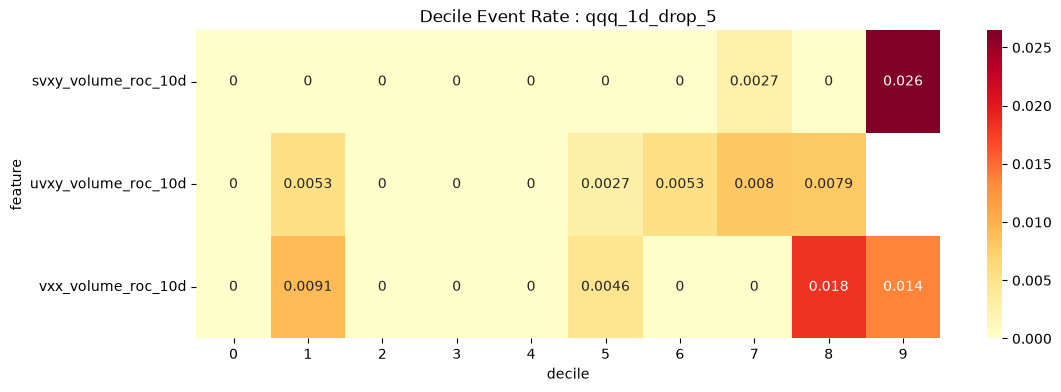

In [37]:
# デシルごとのイベント率をヒートマップで可視化する
target = "qqq_1d_drop_5"
# 可視化するターゲットを指定する
plot_df = (decile_df[decile_df["target"] == target])
# ピボットテーブルを作成する
pivot_df = plot_df.pivot(
    index="feature",
    columns="decile",
    values="event_rate"
)
plt.figure(figsize=(12, 4))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="YlOrRd"
)
plt.title(f"Decile Event Rate : {target}")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"14_decile_event_rate_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 15. Decile別Liftヒートマップ

##### 目的

どのETFのROCが
急落イベントに対して最も強いLiftを持つか確認する。

saved: /workspace/data/figures/15_decile_lift_2010-01-01_2026-10-25.png


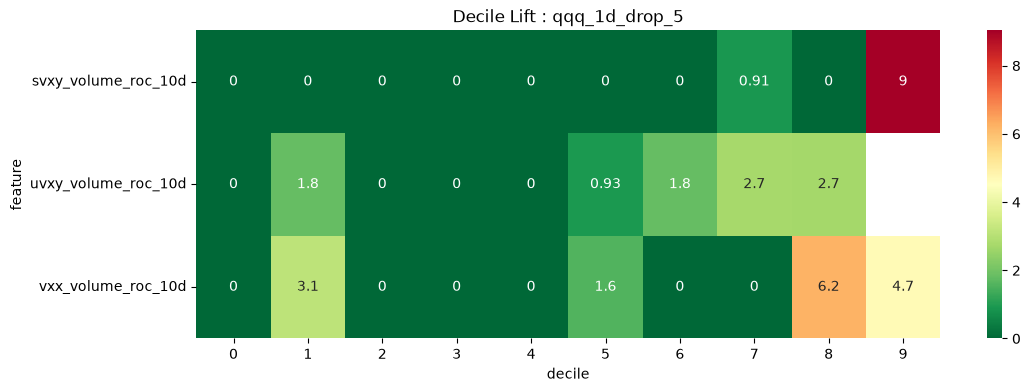

In [38]:
# デシルごとのリフトをヒートマップで可視化する
target = "qqq_1d_drop_5"
plot_df = (decile_df[decile_df["target"] == target])
pivot_df = plot_df.pivot(
    index="feature",
    columns="decile",
    values="lift"
)
plt.figure(figsize=(12, 4))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="RdYlGn_r"
)
plt.title(f"Decile Lift : {target}")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"15_decile_lift_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 16. Later1候補抽出

##### 目的

Later1で利用可能な
ROCベースシグナルを抽出する。

In [39]:
# デシル9かつサンプル数が20以上の候補をリフト順に表示
later1_candidates = (
    decile_df
    .query("decile == 9 and samples >= 20")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"16_top_later1_candidates_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = later1_candidates.copy()
df.to_csv(output_path)
display(later1_candidates)

,feature,target,decile,samples,event_rate,baseline,lift
56,svxy_volume_roc_10d,qqq_1d_drop_5,9,378,0.026455,0.002929,9.031339
86,vxx_volume_roc_10d,qqq_1d_drop_5,9,219,0.013699,0.002929,4.676502
46,svxy_volume_roc_10d,qqq_1d_drop_3,9,378,0.089947,0.019603,4.588335
76,vxx_volume_roc_10d,qqq_1d_drop_3,9,219,0.073059,0.019603,3.726867
36,svxy_volume_roc_10d,qqq_1d_drop_2,9,378,0.187831,0.053628,3.502490
66,vxx_volume_roc_10d,qqq_1d_drop_2,9,219,0.159817,0.053628,2.980124


#### 17. Volume Level × Volume ROC 複合シグナル分析

##### 目的

出来高水準(Z-score)と
出来高モメンタム(ROC)を組み合わせた場合に

QQQ急落イベントの発生率が
さらに上昇するか検証する。

Later1の複合条件候補を探索する。

In [40]:
LEVEL_FEATURES = ["uvxy_volume_z", "svxy_volume_z", "vxx_volume_z"]
ROC_FEATURES = ["uvxy_volume_roc_10d", "svxy_volume_roc_10d", "vxx_volume_roc_10d"]
TARGETS = ["qqq_1d_drop_2", "qqq_1d_drop_3", "qqq_1d_drop_5"]

#### 18. ROC Top Decile フラグ作成

##### 目的

出来高ROC上位10%を
シグナルとして利用する。

In [41]:
# ROC_FEATURESの各特徴量について、上位デシルフラグを作成する
for feature in ROC_FEATURES:
    # 各特徴量の上位デシルを計算する
    decile_col = (f"{feature}_decile")
    top_flag_col = (f"{feature}_top_decile")
    research_df[top_flag_col] = (research_df[decile_col] == 9).astype(int)

#### 19. Level × ROC 複合イベントスタディ

##### 目的

出来高異常と
出来高増加速度の同時発生を評価する。

In [42]:
# 分析対象のレベル特徴量とROC特徴量の組み合わせごとに、指定した閾値以上のサンプルに対するイベント率とベースラインの比較を行う
LEVEL_THRESHOLDS = [2, 3, 4]
rows = []
# 結果を格納するリストを初期化
for level_feature, roc_feature in zip(LEVEL_FEATURES, ROC_FEATURES):
    # ROC特徴量の上位デシルフラグ列名を作成
    roc_flag = (f"{roc_feature}_top_decile")
    # レベル特徴量の閾値ごとにサンプルを抽出
    for threshold in LEVEL_THRESHOLDS:
        sample_df = research_df[
            (research_df[level_feature] >= threshold)
            &
            (research_df[roc_flag] == 1)
        ]
        # 各ターゲットに対してイベント率とベースラインを計算
        for target in TARGETS:
            # ベースラインを計算
            baseline = (research_df[target].mean())
            # サンプルに対するイベント率を計算
            event_rate = (sample_df[target].mean())
            # 結果を辞書にまとめてリストに追加
            rows.append({
                "level_feature": level_feature,
                "roc_feature": roc_feature,
                "threshold": threshold,
                "target": target,
                "samples":len(sample_df),
                "event_rate": event_rate,
                "baseline": baseline,
                "lift": (event_rate / baseline) if baseline > 0 else np.nan
            })
# 結果をデータフレームに変換
combo_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"19_Level_ROC_Composite_Event_Study_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = combo_df.copy()
df.to_csv(output_path)                        
display(combo_df)

,level_feature,roc_feature,threshold,target,samples,event_rate,baseline,lift
0,uvxy_volume_z,uvxy_volume_roc_10d,2,qqq_1d_drop_2,0,NaN,0.053628,NaN
1,uvxy_volume_z,uvxy_volume_roc_10d,2,qqq_1d_drop_3,0,NaN,0.019603,NaN
2,uvxy_volume_z,uvxy_volume_roc_10d,2,qqq_1d_drop_5,0,NaN,0.002929,NaN
3,uvxy_volume_z,uvxy_volume_roc_10d,3,qqq_1d_drop_2,0,NaN,0.053628,NaN
4,uvxy_volume_z,uvxy_volume_roc_10d,3,qqq_1d_drop_3,0,NaN,0.019603,NaN
5,uvxy_volume_z,uvxy_volume_roc_10d,3,qqq_1d_drop_5,0,NaN,0.002929,NaN
6,uvxy_volume_z,uvxy_volume_roc_10d,4,qqq_1d_drop_2,0,NaN,0.053628,NaN
7,uvxy_volume_z,uvxy_volume_roc_10d,4,qqq_1d_drop_3,0,NaN,0.019603,NaN
8,uvxy_volume_z,uvxy_volume_roc_10d,4,qqq_1d_drop_5,0,NaN,0.002929,NaN
9,svxy_volume_z,svxy_volume_roc_10d,2,qqq_1d_drop_2,156,0.243590,0.053628,4.542232


#### 20. 複合シグナルランキング

##### 目的

Later1候補を抽出する。

In [43]:
# サンプル数が20以上の組み合わせを抽出し、リフトの降順でソートして上位50件を表示
combo_rank_df = (
    combo_df
    .query("samples >= 20")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"20_combo_rank_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = combo_rank_df.copy()
df.to_csv(output_path)
# 上位50件を表示
display(combo_rank_df.head(50))

,level_feature,roc_feature,threshold,target,samples,event_rate,baseline,lift
17,svxy_volume_z,svxy_volume_roc_10d,4,qqq_1d_drop_5,30,0.100000,0.002929,34.138462
14,svxy_volume_z,svxy_volume_roc_10d,3,qqq_1d_drop_5,82,0.085366,0.002929,29.142589
11,svxy_volume_z,svxy_volume_roc_10d,2,qqq_1d_drop_5,156,0.057692,0.002929,19.695266
23,vxx_volume_z,vxx_volume_roc_10d,3,qqq_1d_drop_5,36,0.055556,0.002929,18.965812
20,vxx_volume_z,vxx_volume_roc_10d,2,qqq_1d_drop_5,68,0.044118,0.002929,15.061086
16,svxy_volume_z,svxy_volume_roc_10d,4,qqq_1d_drop_3,30,0.200000,0.019603,10.202299
13,svxy_volume_z,svxy_volume_roc_10d,3,qqq_1d_drop_3,82,0.170732,0.019603,8.709280
22,vxx_volume_z,vxx_volume_roc_10d,3,qqq_1d_drop_3,36,0.166667,0.019603,8.501916
15,svxy_volume_z,svxy_volume_roc_10d,4,qqq_1d_drop_2,30,0.400000,0.053628,7.458824
10,svxy_volume_z,svxy_volume_roc_10d,2,qqq_1d_drop_3,156,0.141026,0.019603,7.193929


#### 21. QQQ -5% 特化分析

##### 目的

暴落シグナル候補を確認する。

In [44]:
# "qqq_1d_drop_5"ターゲットに対するクラッシュイベントのリフト上位の組み合わせを抽出して表示
crash_df = (
    combo_df[combo_df["target"] == "qqq_1d_drop_5"]
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"21_qqq_crash_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = crash_df.copy()
df.to_csv(output_path)
display(crash_df)

,level_feature,roc_feature,threshold,target,samples,event_rate,baseline,lift
26,vxx_volume_z,vxx_volume_roc_10d,4,qqq_1d_drop_5,17,0.117647,0.002929,40.162896
17,svxy_volume_z,svxy_volume_roc_10d,4,qqq_1d_drop_5,30,0.100000,0.002929,34.138462
14,svxy_volume_z,svxy_volume_roc_10d,3,qqq_1d_drop_5,82,0.085366,0.002929,29.142589
11,svxy_volume_z,svxy_volume_roc_10d,2,qqq_1d_drop_5,156,0.057692,0.002929,19.695266
23,vxx_volume_z,vxx_volume_roc_10d,3,qqq_1d_drop_5,36,0.055556,0.002929,18.965812
20,vxx_volume_z,vxx_volume_roc_10d,2,qqq_1d_drop_5,68,0.044118,0.002929,15.061086
2,uvxy_volume_z,uvxy_volume_roc_10d,2,qqq_1d_drop_5,0,NaN,0.002929,NaN
5,uvxy_volume_z,uvxy_volume_roc_10d,3,qqq_1d_drop_5,0,NaN,0.002929,NaN
8,uvxy_volume_z,uvxy_volume_roc_10d,4,qqq_1d_drop_5,0,NaN,0.002929,NaN


#### 22. Lift ヒートマップ

##### 目的

出来高異常レベルと
ROC上位10%の組み合わせを比較する。

saved: /workspace/data/figures/22_level_roc_lift_2010-01-01_2026-10-25.png


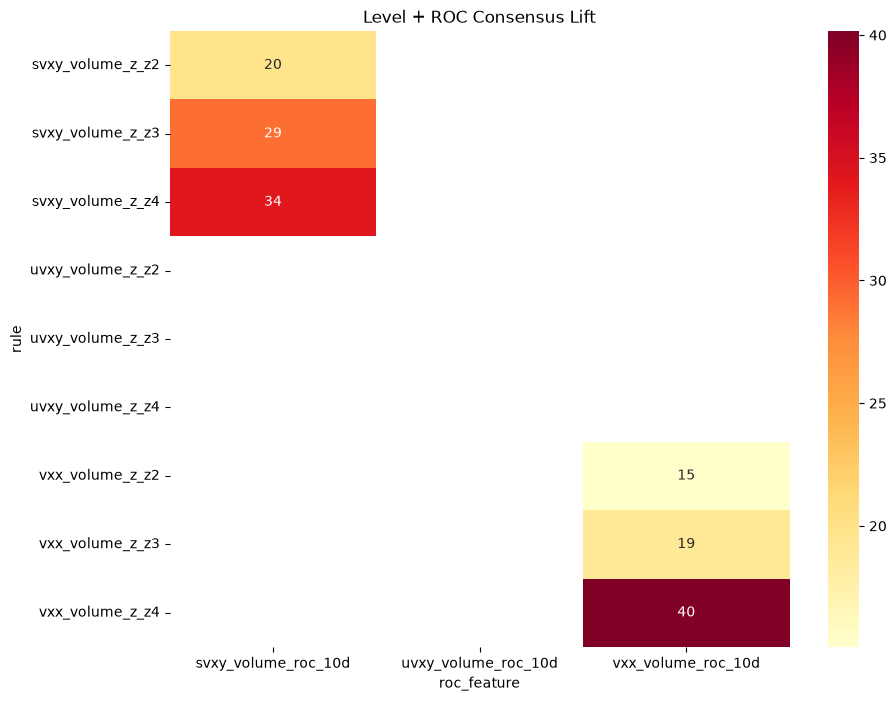

In [45]:
# "qqq_1d_drop_5"ターゲットに対するクラッシュイベントのリフトをヒートマップで可視化
plot_df = combo_df[combo_df["target"] == "qqq_1d_drop_5"]
plot_df["rule"] = (plot_df["level_feature"] + "_z" +plot_df["threshold"].astype(str))
pivot_df = plot_df.pivot(
    index="rule",
    columns="roc_feature",
    values="lift"
)
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_df, annot=True, cmap="YlOrRd")
plt.title("Level + ROC Consensus Lift")
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"22_level_roc_lift_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 23. Later1候補抽出

##### 目的

最終的なアラート候補となる
複合シグナルを抽出する。

In [46]:
# "qqq_1d_drop_5"ターゲットに対するクラッシュイベントのリフトが高い候補を抽出
later1_candidates = (
    combo_df
    .query("target == 'qqq_1d_drop_5' and samples >= 20")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"22_later1_candidates_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = later1_candidates.copy()
df.to_csv(output_path)
display(
    later1_candidates
)

,level_feature,roc_feature,threshold,target,samples,event_rate,baseline,lift
17,svxy_volume_z,svxy_volume_roc_10d,4,qqq_1d_drop_5,30,0.100000,0.002929,34.138462
14,svxy_volume_z,svxy_volume_roc_10d,3,qqq_1d_drop_5,82,0.085366,0.002929,29.142589
11,svxy_volume_z,svxy_volume_roc_10d,2,qqq_1d_drop_5,156,0.057692,0.002929,19.695266
23,vxx_volume_z,vxx_volume_roc_10d,3,qqq_1d_drop_5,36,0.055556,0.002929,18.965812
20,vxx_volume_z,vxx_volume_roc_10d,2,qqq_1d_drop_5,68,0.044118,0.002929,15.061086


#### 24. シグナル比較分析

##### 目的

現時点で最も有力な2種類のシグナル

- SVXY Level + ROC
- SVXY + VXX コンセンサス

を同一条件で比較する。

Later1コアシグナル候補を決定する。

In [47]:
TARGETS = ["qqq_1d_drop_2", "qqq_1d_drop_3", "qqq_1d_drop_5"]

#### 25. 比較対象シグナル作成

##### 目的

Later1候補シグナルを定義する。

In [48]:
# シグナル列の作成: svxyのレベルROCとvxxとの組み合わせ
research_df["signal_svxy_level_roc"] = (
    (research_df["svxy_volume_z"] >= 3)
    &
    (research_df["svxy_volume_roc_10d_decile"] == 9)
).astype(int)
# シグナル列の作成: svxyとvxxのボリュームZスコアの組み合わせ
research_df["signal_svxy_vxx"] = (
    (research_df["svxy_volume_z"] >= 3)
    &
    (research_df["vxx_volume_z"] >= 3)
).astype(int)

#### 26. イベントスタディ

##### 目的

各シグナル発生時の

- 発生回数
- イベント率
- Lift

を比較する。

In [49]:
# 
rows = []
SIGNALS = ["signal_svxy_level_roc", "signal_svxy_vxx"]
# 各シグナルに対してターゲットのイベント率とリフトを計算
for signal in SIGNALS:
    # シグナルが1のサンプルを抽出
    sample_df = research_df[research_df[signal] == 1]
    # 各ターゲットに対してイベント率とリフトを計算
    for target in TARGETS:
        # ベースラインの計算
        baseline = (research_df[target].mean())
        # シグナルが1のサンプルにおけるイベント率の計算
        event_rate = (sample_df[target].mean())
        # リフトの計算は後で行う
        rows.append({
            "signal": signal,
            "samples": len(sample_df),
            "target": target,
            "event_rate": event_rate,
            "baseline": baseline,
            "lift": (event_rate / baseline) if baseline > 0 else np.nan
        })
# シグナルごとの比較結果をデータフレームにまとめて表示
signal_compare_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"26_signal_compare_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = signal_compare_df.copy()
df.to_csv(output_path)
display(signal_compare_df)

,signal,samples,target,event_rate,baseline,lift
0,signal_svxy_level_roc,82,qqq_1d_drop_2,0.292683,0.053628,5.457676
1,signal_svxy_level_roc,82,qqq_1d_drop_3,0.170732,0.019603,8.709280
2,signal_svxy_level_roc,82,qqq_1d_drop_5,0.085366,0.002929,29.142589
3,signal_svxy_vxx,28,qqq_1d_drop_2,0.464286,0.053628,8.657563
4,signal_svxy_vxx,28,qqq_1d_drop_3,0.250000,0.019603,12.752874
5,signal_svxy_vxx,28,qqq_1d_drop_5,0.071429,0.002929,24.384615


#### 27. Precision評価

##### 目的

Later1アラート発生時に

本当に急落した割合を確認する。

In [50]:
# シグナルごとのリフトをターゲットごとに降順でソートして表示
precision_df = (signal_compare_df.sort_values(["target", "lift"],ascending=False))
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"27_precision_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = precision_df.copy()
df.to_csv(output_path)
display(precision_df)

,signal,samples,target,event_rate,baseline,lift
2,signal_svxy_level_roc,82,qqq_1d_drop_5,0.085366,0.002929,29.142589
5,signal_svxy_vxx,28,qqq_1d_drop_5,0.071429,0.002929,24.384615
4,signal_svxy_vxx,28,qqq_1d_drop_3,0.250000,0.019603,12.752874
1,signal_svxy_level_roc,82,qqq_1d_drop_3,0.170732,0.019603,8.709280
3,signal_svxy_vxx,28,qqq_1d_drop_2,0.464286,0.053628,8.657563
0,signal_svxy_level_roc,82,qqq_1d_drop_2,0.292683,0.053628,5.457676


#### 28. Lift比較ヒートマップ

##### 目的

シグナルごとの性能差を可視化する。

saved: /workspace/data/figures/28_later1_candidate_comparison_2010-01-01_2026-10-25.png


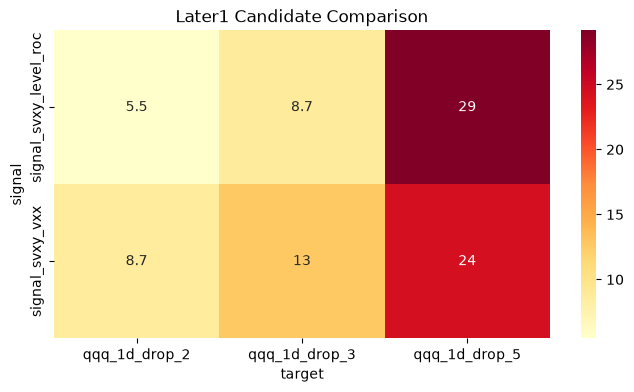

In [51]:
# シグナルごとのリフトをターゲットごとにピボットしてヒートマップを作成
pivot_df = signal_compare_df.pivot(
    index="signal",
    columns="target",
    values="lift"
)
plt.figure(figsize=(8, 4))
sns.heatmap(
    pivot_df,
    annot=True,
    cmap="YlOrRd"
)
plt.title("Later1 Candidate Comparison")

# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"28_later1_candidate_comparison_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
plt.show()

#### 29. Signal Strength比較

##### 目的

Later1初版で採用すべき
最有力シグナルを決定する。

In [52]:
# 'qqq_1d_drop_5' ターゲットに対するシグナルのリフトを降順で表示
winner_df = (
    signal_compare_df
    .query("target == 'qqq_1d_drop_5'")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"29_signal_strength_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = winner_df.copy()
df.to_csv(output_path)
display(winner_df)

,signal,samples,target,event_rate,baseline,lift
2,signal_svxy_level_roc,82,qqq_1d_drop_5,0.085366,0.002929,29.142589
5,signal_svxy_vxx,28,qqq_1d_drop_5,0.071429,0.002929,24.384615


#### 30. Later1設計候補

##### 目的

実装候補を整理する。

In [53]:
winner_df = (
    signal_compare_df
    .query("target == 'qqq_1d_drop_5'")
    .sort_values("lift", ascending=False)
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"30_layer1_candidate_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = winner_df.copy()
df.to_csv(output_path)
display(winner_df)

,signal,samples,target,event_rate,baseline,lift
2,signal_svxy_level_roc,82,qqq_1d_drop_5,0.085366,0.002929,29.142589
5,signal_svxy_vxx,28,qqq_1d_drop_5,0.071429,0.002929,24.384615


#### 31. Time Stability Analysis

## 目的

シグナル効果が

- 2009-2015
- 2016-2020
- 2021-2026

の各期間で再現されるか確認する。

Later1候補の頑健性を評価する。

In [54]:
# 研究用データフレームの日付列を datetime 型に変換し、分析期間を定義する
research_df["date"] = pd.to_datetime(research_df["date"])
# 分析期間を定義するための期間リストを作成する
periods = [
    ("2009-2015", "2009-01-01", "2015-12-31"),
    ("2016-2020", "2016-01-01", "2020-12-31"),
    ("2021-2026", "2021-01-01", "2026-12-31")
]

#### 32. シグナル定義

##### 目的

検証対象シグナルを定義する。

In [55]:
# later1_signal を計算する
research_df["later1_signal"] = (
    (research_df["svxy_volume_z"] >= 3)
    &
    (research_df["svxy_volume_roc_10d_decile"] == 9)
).astype(int)

#### 33. 期間別Lift分析

##### 目的

各期間ごとの

- サンプル数
- イベント率
- Lift

を比較する。

In [56]:
# ターゲット「qqq_1d_drop_5」に関する「later1_signal」の安定性を、期間ごとに算出する。
rows = []
TARGET = "qqq_1d_drop_5"
# 期間ごとのラベルと開始日、終了日を定義したリスト
for label, start, end in periods:
    # 指定された期間に該当するデータを抽出する
    period_df = research_df[
        (research_df["date"] >= start)
        &
        (research_df["date"] <= end)
    ]
    # 指定された期間のターゲットの平均値を計算する
    baseline = (period_df[TARGET].mean())
    # 「later1_signal」が1のデータを抽出する
    signal_df = period_df[period_df["later1_signal"] == 1]
    # 「later1_signal」が1のデータにおけるターゲットの平均値を計算する
    event_rate = (signal_df[TARGET].mean())
    # リフトを計算するための初期値を設定する
    lift = np.nan
    # リフトを計算するための初期値を設定する
    if baseline > 0:
        lift = (event_rate / baseline)
    # 計算結果を辞書に追加する
    rows.append({
        "period": label,
        "samples": len(signal_df),
        "baseline": baseline,
        "event_rate": event_rate,
        "lift": lift
    })
# 辞書のリストからデータフレームを作成する
stability_df = pd.DataFrame(rows)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"33_Lift_analysis_period_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = stability_df.copy()
df.to_csv(output_path)
display(stability_df)

,period,samples,baseline,event_rate,lift
0,2009-2015,13,0.001746,0.076923,44.051282
1,2016-2020,41,0.004766,0.073171,15.353659
2,2021-2026,28,0.002738,0.107143,39.133929


#### 34. Fisher Exact Test

##### 目的

シグナルと急落イベントが
統計的に独立であるか検定する。

帰無仮説：

シグナル発生と急落発生は無関係

In [57]:
# later1_signalに基づき、目的変数に関するオッズ比およびp値を算出する。
TARGET = "qqq_1d_drop_5"
signal_df = research_df[research_df["later1_signal"] == 1]
non_signal_df = research_df[research_df["later1_signal"] == 0]
a = signal_df[TARGET].sum()
b = len(signal_df) - a
c = non_signal_df[TARGET].sum()
d = len(non_signal_df) - c
table = [[a, b], [c, d]]
# フィッシャーの正確確率検定を実行するための2x2分割表を作成
odds_ratio, p_value = fisher_exact(table)
# オッズ比およびp値を出力
print(f"odds_ratio = {odds_ratio:.4f}")
print(f"p_value = {p_value:.8f}")

odds_ratio = 67.6667
p_value = 0.00000000


#### 35. Contingency Table確認

##### 目的

Fisher検定で使用した
2×2分割表を確認する。

In [58]:
# 2x2分割表をDataFrameとして表示
contingency_df = pd.DataFrame(
    table,
    index=["signal", "no_signal"],
    columns=["crash", "no_crash"]
)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"35_contingency_table_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = contingency_df.copy()
df.to_csv(output_path)
display(contingency_df)


,crash,no_crash
signal,7,75
no_signal,6,4350


#### 37. Bootstrap Lift

##### 目的

Lift推定値の安定性を確認する。

95%信頼区間を算出する。

In [59]:
# BootstrapによるLift分析
BOOTSTRAP_ITER = 1000
lifts = []
signal_df = research_df[research_df["later1_signal"] == 1]
baseline = (research_df[TARGET].mean())
# Signalが1のデータを抽出し、ベースラインを計算
for _ in range(BOOTSTRAP_ITER):
    # Signalが1のデータからブートストラップサンプルを作成
    sample = signal_df.sample(frac=1,replace=True)
    # ブートストラップサンプルからイベント率を計算
    event_rate = (sample[TARGET].mean())
    # Liftを計算してリストに追加
    lifts.append(event_rate / baseline)
# ブートストラップによるLiftの分布が完成
lift_mean = np.mean(lifts)
# ブートストラップによるLiftの平均を計算
ci_low = np.percentile(lifts, 2.5)
# ブートストラップによるLiftの95%信頼区間の下限を計算
ci_high = np.percentile(lifts, 97.5)
# ブートストラップによるLiftの95%信頼区間の上限を計算
print(f"Lift Mean : {lift_mean:.2f}")
print(f"95% CI : [{ci_low:.2f}, {ci_high:.2f}]")

Lift Mean : 29.31
95% CI : [8.33, 49.96]


In [60]:
from scipy.stats import fisher_exact

odds, p = fisher_exact(table)

print(
    f"odds={odds}"
)

print(
    f"p={p:.30e}"
)

odds=67.66666666666667
p=8.908401842348237024199518132748e-10


# VIX Index Correlation V5 検証レポート

## 検証仮説

V4では「出来高異常水準（Volume Z-Score）」がQQQ急落の先行シグナルとなることを確認した。

V5では以下の仮説を検証した。

- 出来高水準よりも出来高増加速度（Momentum）の方が有効ではないか
- SVXY・VXX・UVXYの出来高変化率やROCに情報価値が存在するか
- 出来高水準と出来高モメンタムを組み合わせることで予測精度が向上するか

---

## 実施内容

以下の特徴量を作成した。

- 出来高変化率（1日、3日、5日、10日）
- 出来高ROC（1日、3日、5日、10日）
- 出来高Z-Score変化量
- 出来高Z-Score

目的変数は

- QQQ翌日 -2%
- QQQ翌日 -3%
- QQQ翌日 -5%

とした。

ROC-AUC、Lift分析、Decile分析を実施した。

---

## 検証結果

最も高いROC-AUCを示した特徴量は

- SVXY Volume ROC 10d
- AUC = 0.950

であった。

SVXYの出来高増加速度は単なる出来高異常よりも強い説明力を持つことが確認された。

Decile分析では、

- SVXY Volume ROC 10d Top Decile

がQQQ翌日-5%急落に対して

- Lift = 9.03

を示した。

さらに、

- SVXY_Z >= 3
- SVXY_ROC_10D Top Decile

を組み合わせた複合シグナルでは

- event_rate = 8.54%
- Lift = 29.14

となり、

- SVXY_Z >= 3 AND VXX_Z >= 3
- Lift = 24.38

を上回った。

---

## 統計的検定

Fisher Exact Test を実施した。

- Odds Ratio = 67.67
- p-value = 8.9 × 10^-10

帰無仮説

「シグナル発生とQQQ急落は無関係」

は棄却された。

---

## 頑健性検証

期間別Lift分析

- 2009-2015 : Lift = 44.1
- 2016-2020 : Lift = 15.4
- 2021-2026 : Lift = 39.1

全期間で有意なLiftが維持された。

Bootstrap検証

- Mean Lift = 29.31
- 95% CI = [8.33, 49.96]

下限でもLiftが8倍超であり、シグナルの有効性が確認された。

---

## 結論

V5の結果から、

SVXY出来高異常水準とSVXY出来高モメンタムの組み合わせは、QQQ翌日急落を示唆する統計的に有意かつ期間安定性を持つ先行警戒シグナルである可能性が高い。

現時点で最有力のLater1候補は

SVXY_Z >= 3 AND SVXY_ROC_10D Top Decile

である。